# Comparación de modelos generativos en MNIST

In [1]:
import sys
from pathlib import Path

try:
    from google.colab import drive
except ImportError:
    project_root = Path.cwd().parents[0]
else:
    drive.mount("/content/drive", force_remount=True)
    project_root = Path("/content/drive/MyDrive/tfg_copia")

assert (project_root / "ebm").is_dir(), f"raíz mal resuelta: {project_root}"
sys.path.insert(0, str(project_root))
print("Project root:", project_root)

import json
import time
import random
import unicodedata

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy import linalg

from data import get_mnist_loaders
from utils import plot_image_grid, to_01, noise_like_images, sample_initial_latents

from ebm.models import EnergyModelPCD, EnergyUNet
from ebm.sampling import langevin_sampling, annealed_langevin

from diffusion.score_models import ScoreNet
from diffusion.processes import VEProcess
from diffusion.samplers import euler_maruyama_integrator


def set_seed(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.cuda.manual_seed_all(semilla)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

Mounted at /content/drive
Project root: /content/drive/MyDrive/tfg_copia
DATA_DIR: /content/drive/MyDrive/tfg_copia/data
device: cuda


In [2]:
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader

NVIDIA A100-SXM4-80GB, 81920 MiB


## Configuración

In [ ]:
CFG = dict(
    seed            = 42,
    n_muestras      = 10_000,
    k_vecinos       = 3,          
    usar_inception  = False,     
    regenerar       = False,      

    batch_pcd       = 500,
    batch_dsm       = 250,
    batch_difusion  = 50,
    clf_epocas      = 3,

    prior_difusion  = "sigma",
)

IMG_SHAPE = (1, 28, 28)

dir_salida = project_root / "results" / "comparacion"
dir_salida.mkdir(parents=True, exist_ok=True)

set_seed(CFG["seed"])


def slug(nombre):
    s = unicodedata.normalize("NFKD", nombre).encode("ascii", "ignore").decode()
    return "".join(c if c.isalnum() else "_" for c in s.lower()).strip("_")


def guardar_fig(nombre):
    plt.savefig(dir_salida / f"{nombre}.png", dpi=150, bbox_inches="tight")


print("salida:", dir_salida)
CFG

salida: /content/drive/MyDrive/tfg_copia/results/comparacion


{'seed': 42,
 'n_muestras': 10000,
 'k_vecinos': 3,
 'usar_inception': False,
 'regenerar': False,
 'batch_pcd': 500,
 'batch_dsm': 250,
 'batch_difusion': 50,
 'clf_epocas': 3,
 'prior_difusion': 'sigma'}

## Carga de modelos

In [4]:
RUTAS = {
    "PCD": dict(
        ckpt=project_root / "checkpoints" / "pcd" / "last.pt",
        res=project_root / "results" / "pcd" / "results.json",
    ),
    "EBM energía (DSM)": dict(
        ckpt=project_root / "checkpoints" / "energy_dsm" / "last.pt",
        res=project_root / "results" / "energy_dsm" / "results.json",
    ),
    "Difusión VE-SDE": dict(
        ckpt=project_root / "checkpoints" / "diffusion" / "last.pt",
        res=project_root / "results" / "diffusion" / "results.json",
    ),
}

disponibles = []

for nombre, r in RUTAS.items():
    hay_ckpt = r["ckpt"].exists()
    hay_res = r["res"].exists()
    if hay_ckpt and hay_res:
        disponibles.append(nombre)
    print(
        f"{nombre:22s} "
        f"ckpt {'OK   ' if hay_ckpt else 'FALTA'} | "
        f"results {'OK   ' if hay_res else 'FALTA'}"
    )

print()
print("modelos disponibles:", disponibles)

PCD                    ckpt OK    | results OK   
EBM energía (DSM)      ckpt OK    | results OK   
Difusión VE-SDE        ckpt OK    | results OK   

modelos disponibles: ['PCD', 'EBM energía (DSM)', 'Difusión VE-SDE']


In [5]:
checkpoints = {}
configs = {}
historiales = {}

for nombre in disponibles:
    checkpoints[nombre] = torch.load(
        RUTAS[nombre]["ckpt"], map_location=device, weights_only=False
    )
    configs[nombre] = checkpoints[nombre]["cfg"]
    with RUTAS[nombre]["res"].open() as f:
        historiales[nombre] = json.load(f)

    n_ep = len(historiales[nombre]["hist_ep"]["epoch"])
    print(f"{nombre:22s} época {checkpoints[nombre]['epoch']:3d} | {n_ep} épocas en el historial")

PCD                    época  60 | 60 épocas en el historial
EBM energía (DSM)      época  60 | 60 épocas en el historial
Difusión VE-SDE        época  30 | 30 épocas en el historial


In [ ]:
modelos = {}

if "PCD" in disponibles:
    cfg = configs["PCD"]
    m = EnergyModelPCD(
        hidden=cfg["hidden"],
        spectral_norm=cfg["spectral_norm"],
    ).to(device)
    m.load_state_dict(checkpoints["PCD"]["model"])
    modelos["PCD"] = m.eval()

if "EBM energía (DSM)" in disponibles:
    cfg = configs["EBM energía (DSM)"]
    m = EnergyUNet(channels=cfg["channels"]).to(device)
    m.load_state_dict(checkpoints["EBM energía (DSM)"]["ema"])
    modelos["EBM energía (DSM)"] = m.eval()
    sigmas_dsm = checkpoints["EBM energía (DSM)"]["sigmas"].to(device)
    eps_dsm = checkpoints["EBM energía (DSM)"]["eps"]

if "Difusión VE-SDE" in disponibles:
    cfg = configs["Difusión VE-SDE"]
    proceso_ve = VEProcess(sigma=cfg["sigma"])
    m = ScoreNet(
        marginal_prob_std=proceso_ve.sigma_t,
        in_channels=1,
    ).to(device)
    m.load_state_dict(checkpoints["Difusión VE-SDE"]["model"])
    modelos["Difusión VE-SDE"] = m.eval()

n_parametros = {
    nombre: sum(p.numel() for p in m.parameters())
    for nombre, m in modelos.items()
}

for nombre, n in n_parametros.items():
    print(f"{nombre:22s} {n:>10,} parámetros")

PCD                        76,993 parámetros
EBM energía (DSM)       1,980,929 parámetros
Difusión VE-SDE         1,115,425 parámetros


## Datos reales y las dos mitades

In [ ]:
train_loader, test_loader = get_mnist_loaders(
    batch_size=256,
    normalize=False,
    num_workers=2,
)

datos_train = train_loader.dataset.data.float().div(255.0).unsqueeze(1)
etiquetas_train = train_loader.dataset.targets.clone()

N = CFG["n_muestras"]
assert 2 * N <= len(datos_train), "n_muestras es demasiado grande para dos mitades disjuntas"

g = torch.Generator().manual_seed(CFG["seed"])
perm = torch.randperm(len(datos_train), generator=g)

real_A = datos_train[perm[:N]].clone()
real_B = datos_train[perm[N:2 * N]].clone()

print("mitad A:", tuple(real_A.shape), "| mitad B:", tuple(real_B.shape))
print("rango:", real_A.min().item(), "-", real_A.max().item())

mitad A: (10000, 1, 28, 28) | mitad B: (10000, 1, 28, 28)
rango: 0.0 - 1.0


## Generación de muestras

In [8]:
def generar_pcd(n, semilla):
    cfg = configs["PCD"]
    set_seed(semilla)
    trozos = []

    for inicio in range(0, n, CFG["batch_pcd"]):
        b = min(CFG["batch_pcd"], n - inicio)
        x0 = noise_like_images(b, image_shape=IMG_SHAPE, device=device)
        x = langevin_sampling(
            model=modelos["PCD"],
            x_init=x0,
            n_steps=cfg["gen_steps"],
            step_size=cfg["sgld_step_size"],
            noise_scale=cfg["sgld_noise"],
            grad_clip=cfg["sgld_grad_clip"],
        )
        # el PCD trabaja en [-1, 1]
        trozos.append(to_01(x).detach().cpu())

    return torch.cat(trozos).clamp(0, 1)


def generar_energia(n, semilla):
    cfg = configs["EBM energía (DSM)"]
    x = annealed_langevin(
        model=modelos["EBM energía (DSM)"],
        sigmas=sigmas_dsm,
        eps=eps_dsm,
        image_shape=IMG_SHAPE,
        n_steps_per_level=cfg["T"],
        device=device,
        n_samples=n,
        seed=semilla,
        batch_size=CFG["batch_dsm"],
    )
    return x.detach().cpu().clamp(0, 1)


def generar_difusion(n, semilla):
    cfg = configs["Difusión VE-SDE"]
    set_seed(semilla)

    if CFG["prior_difusion"] == "sigma":
        std_inicial = proceso_ve.sigma_t(
            torch.tensor([cfg["t_start"]], device=device)
        ).item()
    else:
        std_inicial = 1.0

    trozos = []

    with torch.no_grad():
        for inicio in range(0, n, CFG["batch_difusion"]):
            b = min(CFG["batch_difusion"], n - inicio)
            x_T = sample_initial_latents(
                n_images=b,
                image_shape=IMG_SHAPE,
                mean=0.0,
                std=std_inicial,
                device=device,
            )
            _, trayectoria = euler_maruyama_integrator(
                x_T,
                t_0=cfg["t_start"],
                t_end=cfg["t_end"],
                n_steps=cfg["n_steps"],
                drift_coefficient=(
                    lambda x_t, t: proceso_ve.reverse_drift(
                        x_t, t, modelos["Difusión VE-SDE"]
                    )
                ),
                diffusion_coefficient=proceso_ve.diffusion_coefficient,
            )
            trozos.append(trayectoria[..., -1].detach().cpu())
            del trayectoria
            if device.type == "cuda":
                torch.cuda.empty_cache()

    return torch.cat(trozos).clamp(0, 1)


GENERADORES = {
    "PCD": generar_pcd,
    "EBM energía (DSM)": generar_energia,
    "Difusión VE-SDE": generar_difusion,
}

In [9]:
muestras = {}
tiempos_muestreo = {}

for nombre in disponibles:
    ruta = dir_salida / f"muestras_{slug(nombre)}.pt"

    if ruta.exists() and not CFG["regenerar"]:
        guardado = torch.load(ruta, weights_only=False)
        if len(guardado["x"]) == CFG["n_muestras"]:
            muestras[nombre] = guardado["x"]
            tiempos_muestreo[nombre] = guardado["segundos"]
            print(f"{nombre:22s} {len(guardado['x']):6d} muestras cargadas de disco "
                  f"({guardado['segundos']:.1f}s en su día)")
            continue
        print(f"{nombre}: el archivo tiene {len(guardado['x'])} muestras, se regenera")

    t0 = time.time()
    x = GENERADORES[nombre](CFG["n_muestras"], CFG["seed"])
    dt = time.time() - t0

    torch.save(
        {"x": x, "segundos": dt, "n": len(x), "semilla": CFG["seed"]},
        ruta,
    )

    muestras[nombre] = x
    tiempos_muestreo[nombre] = dt
    print(f"{nombre:22s} {len(x):6d} muestras en {dt:7.1f}s "
          f"({dt / len(x) * 1000:.1f} ms/muestra)")

PCD                     10000 muestras cargadas de disco (11.0s en su día)
EBM energía (DSM)       10000 muestras cargadas de disco (259.1s en su día)
Difusión VE-SDE         10000 muestras cargadas de disco (1116.3s en su día)


## Clasificador auxiliar

In [10]:
class ClasificadorMNIST(nn.Module):
    def __init__(self, dim_caracteristicas=128):
        super().__init__()

        self.cuerpo = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, dim_caracteristicas), nn.ReLU(),
        )

        self.salida = nn.Linear(dim_caracteristicas, 10)

    def forward(self, x):
        return self.salida(self.cuerpo(x))

    def caracteristicas(self, x):
        return self.cuerpo(x)


ruta_clf = dir_salida / "clasificador_mnist.pt"

set_seed(CFG["seed"])
clf = ClasificadorMNIST().to(device)

if ruta_clf.exists():
    estado = torch.load(ruta_clf, map_location=device, weights_only=False)
    clf.load_state_dict(estado["model"])
    precision_clf = estado["precision_test"]
    print(f"clasificador cargado de disco | precisión en test {precision_clf:.4f}")
else:
    opt_clf = torch.optim.Adam(clf.parameters(), lr=1e-3)

    clf.train()
    for epoca in range(CFG["clf_epocas"]):
        for x, y in train_loader:
            perdida = F.cross_entropy(clf(x.to(device)), y.to(device))
            opt_clf.zero_grad(set_to_none=True)
            perdida.backward()
            opt_clf.step()
        print(f"  época {epoca + 1}/{CFG['clf_epocas']} completada")

    clf.eval()
    with torch.no_grad():
        aciertos = sum(
            (clf(x.to(device)).argmax(1).cpu() == y).sum().item()
            for x, y in test_loader
        )
    precision_clf = aciertos / len(test_loader.dataset)

    torch.save(
        {"model": clf.state_dict(), "precision_test": precision_clf,
         "semilla": CFG["seed"], "epocas": CFG["clf_epocas"]},
        ruta_clf,
    )
    print(f"clasificador entrenado | precisión en test {precision_clf:.4f}")

clf.eval()

clasificador cargado de disco | precisión en test 0.9841


ClasificadorMNIST(
  (cuerpo): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=3136, out_features=128, bias=True)
    (8): ReLU()
  )
  (salida): Linear(in_features=128, out_features=10, bias=True)
)

## Extracción de características

In [11]:
conjuntos = {
    "MNIST mitad B (referencia)": real_B,
    **{nombre: muestras[nombre] for nombre in disponibles},
}


@torch.no_grad()
def extraer_caracteristicas(x, bs=512):
    salida = []
    for i in range(0, len(x), bs):
        salida.append(clf.caracteristicas(x[i:i + bs].to(device)).cpu())
    return torch.cat(salida).numpy().astype(np.float64)


@torch.no_grad()
def probabilidades(x, bs=512):
    salida = []
    for i in range(0, len(x), bs):
        salida.append(F.softmax(clf(x[i:i + bs].to(device)), dim=1).cpu())
    return torch.cat(salida).numpy().astype(np.float64)


caracteristicas = {"MNIST mitad A": extraer_caracteristicas(real_A)}
probs = {"MNIST mitad A": probabilidades(real_A)}

for nombre, x in conjuntos.items():
    caracteristicas[nombre] = extraer_caracteristicas(x)
    probs[nombre] = probabilidades(x)
    print(f"{nombre:28s} {caracteristicas[nombre].shape}")

MNIST mitad B (referencia)   (10000, 128)
PCD                          (10000, 128)
EBM energía (DSM)            (10000, 128)
Difusión VE-SDE              (10000, 128)


## Métricas de distribución

In [ ]:
def fid(f1, f2):
    mu1, mu2 = f1.mean(axis=0), f2.mean(axis=0)
    s1 = np.cov(f1, rowvar=False)
    s2 = np.cov(f2, rowvar=False)

    diff = mu1 - mu2
    covmean, _ = linalg.sqrtm(s1 @ s2, disp=False)

    if np.iscomplexobj(covmean):
        covmean = covmean.real

    return float(diff @ diff + np.trace(s1 + s2 - 2 * covmean))


def kid(f1, f2, n_subconjuntos=100, tam=1000, semilla=0):
    rng = np.random.default_rng(semilla)
    d = f1.shape[1]
    valores = []

    tam = min(tam, len(f1), len(f2))

    for _ in range(n_subconjuntos):
        x = f1[rng.choice(len(f1), tam, replace=False)]
        y = f2[rng.choice(len(f2), tam, replace=False)]

        kxx = (x @ x.T / d + 1.0) ** 3
        kyy = (y @ y.T / d + 1.0) ** 3
        kxy = (x @ y.T / d + 1.0) ** 3

        np.fill_diagonal(kxx, 0.0)
        np.fill_diagonal(kyy, 0.0)

        valores.append(
            kxx.sum() / (tam * (tam - 1))
            + kyy.sum() / (tam * (tam - 1))
            - 2.0 * kxy.mean()
        )

    return float(np.mean(valores)), float(np.std(valores))


def _radio_k(a, b, k, bloque=2000):
    "Distancia al k-ésimo vecino de cada fila de a dentro de b."
    salida = []
    for i in range(0, len(a), bloque):
        d = torch.cdist(a[i:i + bloque], b)
        salida.append(d.kthvalue(k, dim=1).values)
    return torch.cat(salida)


def _cubierto(a, b, radios_b, bloque=2000):
    "Para cada fila de a, si cae dentro del radio de algún punto de b."
    salida = []
    for i in range(0, len(a), bloque):
        d = torch.cdist(a[i:i + bloque], b)
        salida.append((d <= radios_b.unsqueeze(0)).any(dim=1))
    return torch.cat(salida)


def precision_recall(f_real, f_gen, k=3):
    t_real = torch.from_numpy(f_real).float().to(device)
    t_gen = torch.from_numpy(f_gen).float().to(device)

    radios_real = _radio_k(t_real, t_real, k + 1)
    radios_gen = _radio_k(t_gen, t_gen, k + 1)

    precision = _cubierto(t_gen, t_real, radios_real).float().mean().item()
    recall = _cubierto(t_real, t_gen, radios_gen).float().mean().item()

    del t_real, t_gen
    if device.type == "cuda":
        torch.cuda.empty_cache()

    return precision, recall

In [ ]:
f_referencia = caracteristicas["MNIST mitad A"]

tabla_distribucion = {}

for nombre in conjuntos:
    f = caracteristicas[nombre]

    v_fid = fid(f_referencia, f)
    v_kid, v_kid_std = kid(f_referencia, f, semilla=CFG["seed"])
    v_p, v_r = precision_recall(f_referencia, f, k=CFG["k_vecinos"])

    tabla_distribucion[nombre] = dict(
        fid=v_fid, kid=v_kid, kid_std=v_kid_std,
        precision=v_p, recall=v_r,
    )

    print(f"{nombre:28s} FID {v_fid:8.3f} | "
          f"KID {v_kid:8.5f} ± {v_kid_std:.5f} | "
          f"P {v_p:.3f} | R {v_r:.3f}")

print()

/tmp/ipykernel_519/3602372551.py:7: DeprecationWarning: The `disp` argument is deprecated and will be removed in SciPy 1.18.0.
  covmean, _ = linalg.sqrtm(s1 @ s2, disp=False)
/tmp/ipykernel_519/3602372551.py:7: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  covmean, _ = linalg.sqrtm(s1 @ s2, disp=False)


MNIST mitad B (referencia)   FID    0.629 | KID -1.16919 ± 5.50546 | P 0.897 | R 0.901
PCD                          FID  123.140 | KID 426.68412 ± 56.16877 | P 0.686 | R 0.845
EBM energía (DSM)            FID   16.419 | KID 26.23579 ± 11.17365 | P 0.717 | R 0.954
Difusión VE-SDE              FID   25.000 | KID 44.93770 ± 11.04405 | P 0.732 | R 0.863

La primera fila no es un modelo: es la escala con la que se leen las otras.


## Métricas del clasificador

In [14]:
def entropia_normalizada(clases):
    frec = np.bincount(clases, minlength=10) / len(clases)
    frec = frec[frec > 0]
    return float(-(frec * np.log(frec)).sum() / np.log(10))


def distancia_variacion_total(clases, clases_ref):
    p = np.bincount(clases, minlength=10) / len(clases)
    q = np.bincount(clases_ref, minlength=10) / len(clases_ref)
    return float(0.5 * np.abs(p - q).sum())


def mnist_is(p):
    p_media = p.mean(axis=0, keepdims=True)
    kl = (p * (np.log(p + 1e-12) - np.log(p_media + 1e-12))).sum(axis=1)
    return float(np.exp(kl.mean()))


clases = {k: v.argmax(axis=1) for k, v in probs.items()}
confianzas = {k: v.max(axis=1) for k, v in probs.items()}

clases_ref = clases["MNIST mitad A"]

tabla_clasificador = {}

for nombre in conjuntos:
    tabla_clasificador[nombre] = dict(
        confianza=float(confianzas[nombre].mean()),
        entropia=entropia_normalizada(clases[nombre]),
        tv=distancia_variacion_total(clases[nombre], clases_ref),
        mnist_is=mnist_is(probs[nombre]),
    )

    t = tabla_clasificador[nombre]
    print(f"{nombre:28s} confianza {t['confianza']:.3f} | "
          f"entropía {t['entropia']:.3f} | "
          f"TV {t['tv']:.3f} | MNIST-IS {t['mnist_is']:.3f}")

MNIST mitad B (referencia)   confianza 0.983 | entropía 0.999 | TV 0.021 | MNIST-IS 9.468
PCD                          confianza 0.906 | entropía 0.923 | TV 0.247 | MNIST-IS 6.560
EBM energía (DSM)            confianza 0.923 | entropía 0.987 | TV 0.093 | MNIST-IS 7.880
Difusión VE-SDE              confianza 0.910 | entropía 0.985 | TV 0.120 | MNIST-IS 7.589


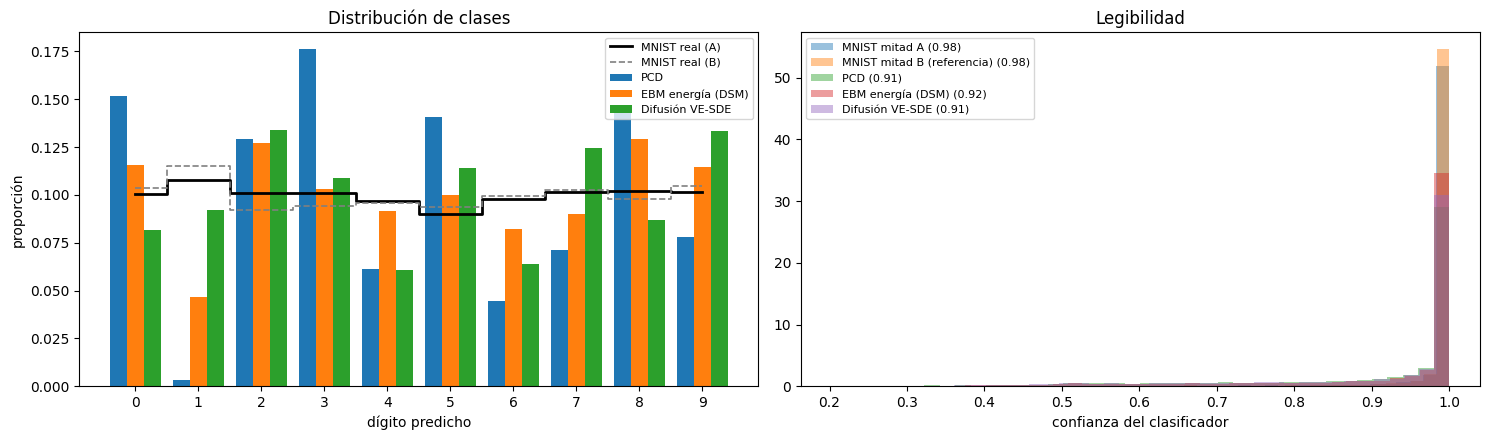

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
digitos = np.arange(10)

def frecuencias(c):
    return np.bincount(c, minlength=10) / len(c)

ancho = 0.8 / len(disponibles)

for j, nombre in enumerate(disponibles):
    ax[0].bar(
        digitos + (j - (len(disponibles) - 1) / 2) * ancho,
        frecuencias(clases[nombre]), ancho, label=nombre,
    )

ax[0].step(digitos, frecuencias(clases["MNIST mitad A"]),
           where="mid", color="k", lw=2, label="MNIST real (A)")
ax[0].step(digitos, frecuencias(clases["MNIST mitad B (referencia)"]),
           where="mid", color="gray", lw=1.2, ls="--", label="MNIST real (B)")

ax[0].set_xticks(digitos)
ax[0].set_xlabel("dígito predicho"); ax[0].set_ylabel("proporción")
ax[0].set_title("Distribución de clases")
ax[0].legend(fontsize=8)

for nombre in ["MNIST mitad A"] + list(conjuntos.keys()):
    ax[1].hist(confianzas[nombre], bins=40, alpha=0.45, density=True,
               label=f"{nombre} ({confianzas[nombre].mean():.2f})")

ax[1].set_xlabel("confianza del clasificador")
ax[1].set_title("Legibilidad"); ax[1].legend(fontsize=8)

plt.tight_layout(); guardar_fig("clases_y_confianza"); plt.show()

## Diversidad y colapso de modos

In [16]:
def distancia_media_pares(f, n_max=2000, semilla=0):
    rng = np.random.default_rng(semilla)
    idx = rng.choice(len(f), min(n_max, len(f)), replace=False)
    t = torch.from_numpy(f[idx]).float().to(device)
    d = torch.cdist(t, t)
    n = len(t)
    media = (d.sum() / (n * (n - 1))).item()
    del t, d
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return media


def fraccion_duplicados(f, umbral_relativo=0.05, n_max=2000, semilla=0):
    rng = np.random.default_rng(semilla)
    idx = rng.choice(len(f), min(n_max, len(f)), replace=False)
    t = torch.from_numpy(f[idx]).float().to(device)
    d = torch.cdist(t, t)
    d.fill_diagonal_(float("inf"))
    vecino = d.min(dim=1).values
    umbral = umbral_relativo * d[d != float("inf")].median()
    frac = (vecino < umbral).float().mean().item()
    del t, d
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return frac


tabla_diversidad = {}

ref_dist = distancia_media_pares(caracteristicas["MNIST mitad A"], semilla=CFG["seed"])

for nombre in conjuntos:
    dm = distancia_media_pares(caracteristicas[nombre], semilla=CFG["seed"])
    fd = fraccion_duplicados(caracteristicas[nombre], semilla=CFG["seed"])

    tabla_diversidad[nombre] = dict(
        distancia_media=dm,
        ratio_vs_real=dm / ref_dist,
        duplicados=fd,
    )

    print(f"{nombre:28s} distancia media {dm:8.3f} "
          f"({dm / ref_dist:5.2f}x la real) | duplicados {fd:.3f}")

MNIST mitad B (referencia)   distancia media   40.987 ( 1.00x la real) | duplicados 0.008
PCD                          distancia media   39.394 ( 0.96x la real) | duplicados 0.000
EBM energía (DSM)            distancia media   39.180 ( 0.96x la real) | duplicados 0.000
Difusión VE-SDE              distancia media   37.478 ( 0.92x la real) | duplicados 0.000


## Memorización

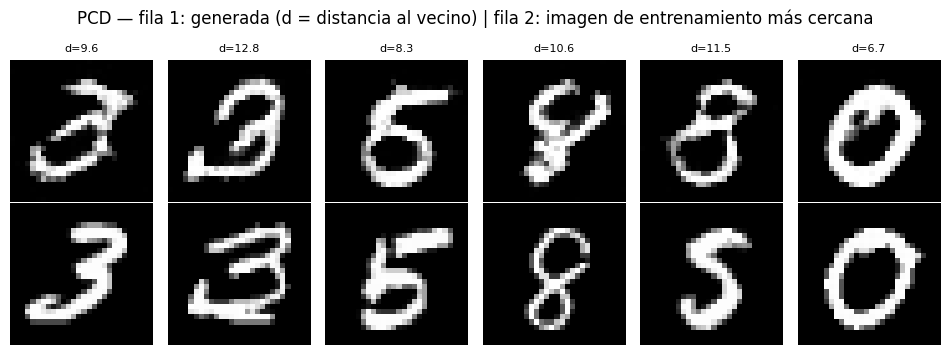

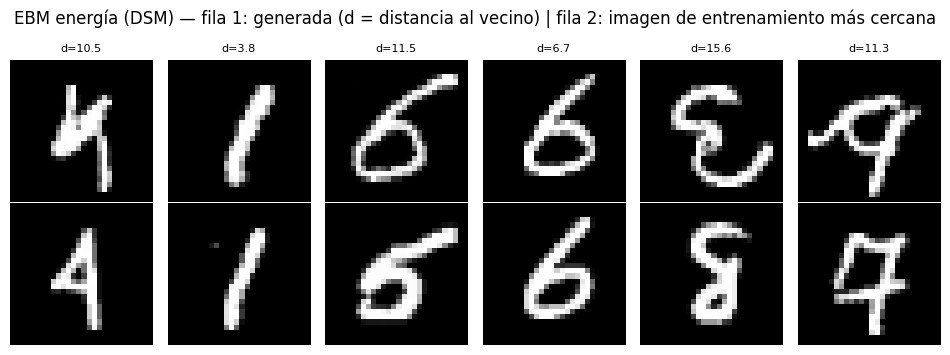

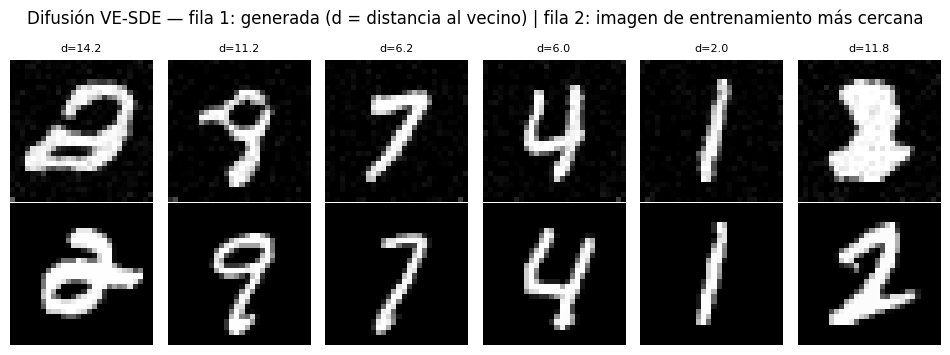

In [17]:
f_train_completo = extraer_caracteristicas(datos_train[:20_000])
t_train = torch.from_numpy(f_train_completo).float().to(device)

n_mostrar = 6

for nombre in disponibles:
    f = torch.from_numpy(caracteristicas[nombre][:n_mostrar]).float().to(device)
    d = torch.cdist(f, t_train)
    vecinos = d.argmin(dim=1).cpu()
    distancias = d.min(dim=1).values.cpu()

    fig, axes = plt.subplots(2, n_mostrar, figsize=(1.6 * n_mostrar, 3.6))

    for j in range(n_mostrar):
        axes[0, j].imshow(muestras[nombre][j, 0], cmap="gray", vmin=0, vmax=1)
        axes[0, j].set_title(f"d={distancias[j]:.1f}", fontsize=8)
        axes[0, j].axis("off")

        axes[1, j].imshow(datos_train[vecinos[j], 0], cmap="gray", vmin=0, vmax=1)
        axes[1, j].axis("off")

    fig.suptitle(
        f"{nombre} — fila 1: generada (d = distancia al vecino) | "
        "fila 2: imagen de entrenamiento más cercana"
    )
    plt.tight_layout()
    guardar_fig(f"memorizacion_{slug(nombre)}")
    plt.show()

del t_train
if device.type == "cuda":
    torch.cuda.empty_cache()

## Curvas de pérdida

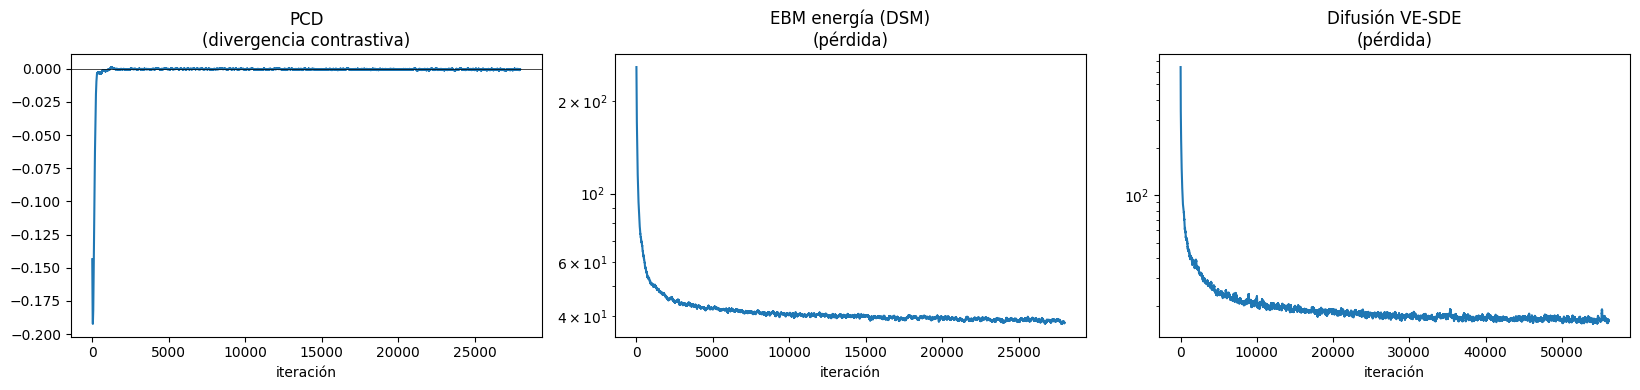

In [ ]:
def suavizar(v, w=100):
    v = np.asarray(v, dtype=float)
    if len(v) < w:
        return v
    return np.convolve(v, np.ones(w) / w, mode="valid")


# --- curvas de pérdida, un panel por modelo ---

fig, ax = plt.subplots(1, len(disponibles), figsize=(5.5 * len(disponibles), 4))
if len(disponibles) == 1:
    ax = [ax]

for j, nombre in enumerate(disponibles):
    h = historiales[nombre]["hist_it"]

    if "cd" in h:
        ax[j].plot(suavizar(h["cd"]), label="divergencia contrastiva")
        ax[j].plot(suavizar(h["reg"]), label="regularización")
        ax[j].axhline(0, color="k", lw=0.5)
        ax[j].legend(fontsize=8)
        ax[j].set_title(f"{nombre}\n(términos de la pérdida)")
    else:
        ax[j].plot(suavizar(h["loss"]))
        ax[j].set_yscale("log")
        ax[j].set_title(f"{nombre}\n(pérdida)")

    ax[j].set_xlabel("iteración")

plt.tight_layout()
guardar_fig("curvas_perdida")
plt.show()



if "PCD" in disponibles:
    h = historiales["PCD"]["hist_it"]
    h_ep = historiales["PCD"]["hist_ep"]

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))

    ax[0].plot(suavizar(h["e_real"]), label=r"$E(x^+)$ datos")
    ax[0].plot(suavizar(h["e_fake"]), label=r"$E(x^-)$ cadenas")
    ax[0].axhline(0, color="k", lw=0.5)
    ax[0].set_xlabel("iteración")
    ax[0].set_ylabel(r"$E_\theta(x)$ media")
    ax[0].set_title("PCD — energías durante el entrenamiento")
    ax[0].legend(fontsize=9)

    ax[1].plot(h_ep["epoch"], h_ep["e_test"], "o-", label="datos de test")
    ax[1].plot(h_ep["epoch"], h_ep["e_noise"], "^-", label="ruido uniforme")
    ax[1].plot(h_ep["epoch"], h_ep["e_buffer"], "s-", label="buffer (cadenas)")
    ax[1].set_yscale("symlog")
    ax[1].set_xlabel("época")
    ax[1].set_ylabel(r"$E_\theta(x)$ media")
    ax[1].set_title("PCD — separación entre datos, cadenas y ruido")
    ax[1].legend(fontsize=9)

    plt.tight_layout()
    guardar_fig("pcd_energias")
    plt.show()

## Estabilidad del entrenamiento

PCD                    dispersión   5.699 →  1.025 | pendiente final  -0.00545 | picos 0.0162
EBM energía (DSM)      dispersión   0.656 →  0.082 | pendiente final  -0.00122 | picos 0.0017
Difusión VE-SDE        dispersión   3.580 →  0.176 | pendiente final  -0.00272 | picos 0.0067


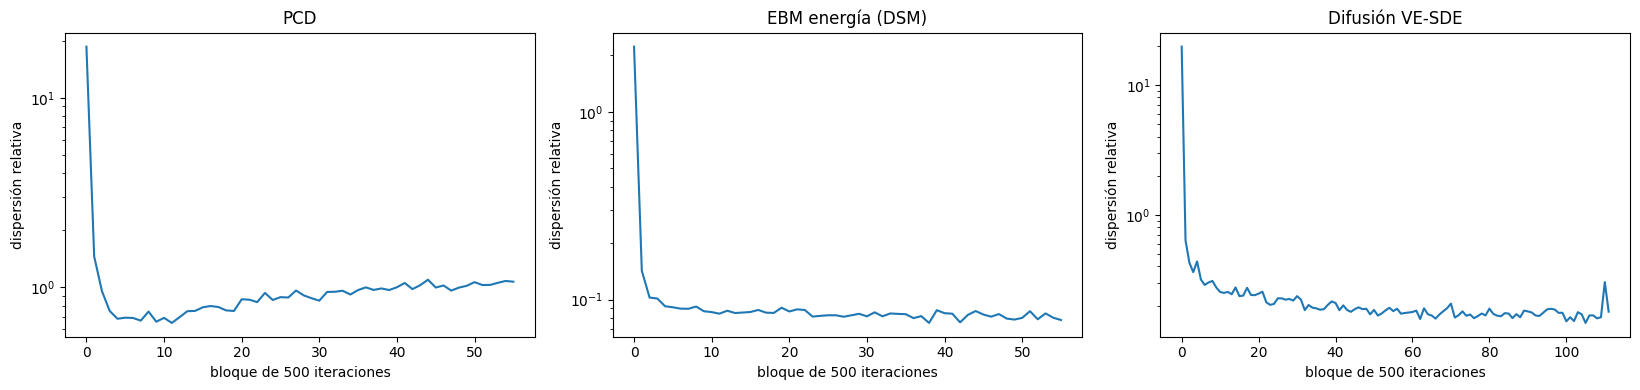

In [19]:
def dispersion_movil(v, ventana=500):
    """Oscilación por bloques, normalizada por la escala global de la señal."""
    v = np.asarray(v, dtype=float)
    escala = np.abs(v).mean()
    n = len(v) // ventana
    bloques = v[:n * ventana].reshape(n, ventana)
    return bloques.std(axis=1) / escala


tabla_estabilidad = {}

for nombre in disponibles:
    h_it = historiales[nombre]["hist_it"]
    h_ep = historiales[nombre]["hist_ep"]

    clave = "cd" if "cd" in h_it else "loss"
    v = np.asarray(h_it[clave], dtype=float)

    # normalizar por la media de los valores absolutos de TODO el entrenamiento
    # evita que el cociente explote cuando la señal converge a cero, como le
    # pasa a la divergencia contrastiva del PCD
    escala = np.abs(v).mean()
    tercio = len(v) // 3

    serie_ep = np.asarray(
        h_ep["loss"] if "loss" in h_ep else h_ep["e_test"],
        dtype=float,
    )
    tramo = serie_ep[int(len(serie_ep) * 2 / 3):]
    pendiente = np.polyfit(np.arange(len(tramo)), tramo, 1)[0]

    tabla_estabilidad[nombre] = dict(
        magnitud_tipica=float(escala),
        dispersion_inicial=float(v[:tercio].std() / escala),
        dispersion_final=float(v[-tercio:].std() / escala),
        pendiente_normalizada=float(pendiente / abs(tramo.mean())),
        fraccion_picos=float((np.abs(v) > 5 * np.median(np.abs(v))).mean()),
    )

    t = tabla_estabilidad[nombre]
    print(f"{nombre:22s} dispersión {t['dispersion_inicial']:7.3f} → {t['dispersion_final']:6.3f} | "
          f"pendiente final {t['pendiente_normalizada']:+9.5f} | "
          f"picos {t['fraccion_picos']:.4f}")

fig, ax = plt.subplots(1, len(disponibles), figsize=(5.5 * len(disponibles), 4))
if len(disponibles) == 1:
    ax = [ax]

for j, nombre in enumerate(disponibles):
    h = historiales[nombre]["hist_it"]
    clave = "cd" if "cd" in h else "loss"

    ax[j].plot(dispersion_movil(h[clave]))
    ax[j].set_yscale("log")
    ax[j].set_xlabel("bloque de 500 iteraciones")
    ax[j].set_ylabel("dispersión relativa")
    ax[j].set_title(nombre)

plt.tight_layout()
guardar_fig("estabilidad_entrenamiento")
plt.show()

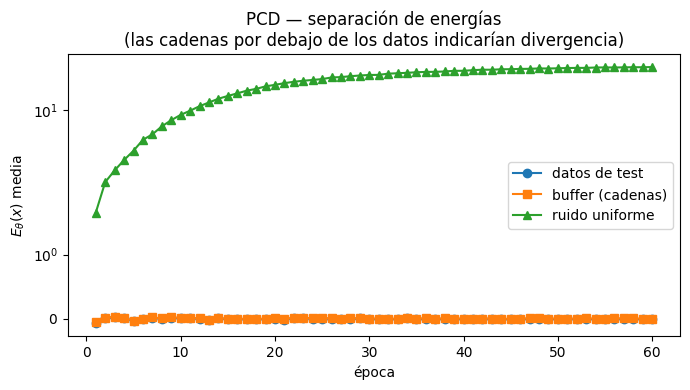

In [ ]:
if "PCD" in disponibles:
    h_ep = historiales["PCD"]["hist_ep"]

    plt.figure(figsize=(7, 4))
    plt.plot(h_ep["epoch"], h_ep["e_test"], "o-", label="datos de test")
    plt.plot(h_ep["epoch"], h_ep["e_buffer"], "s-", label="buffer (cadenas)")
    plt.plot(h_ep["epoch"], h_ep["e_noise"], "^-", label="ruido uniforme")
    plt.yscale("symlog")
    plt.xlabel("época")
    plt.ylabel(r"$E_\theta(x)$ media")
    plt.title("PCD — separación de energías\n(las cadenas por debajo de los datos indicarían divergencia)")
    plt.legend()
    plt.tight_layout()
    guardar_fig("pcd_separacion_energias")
    plt.show()

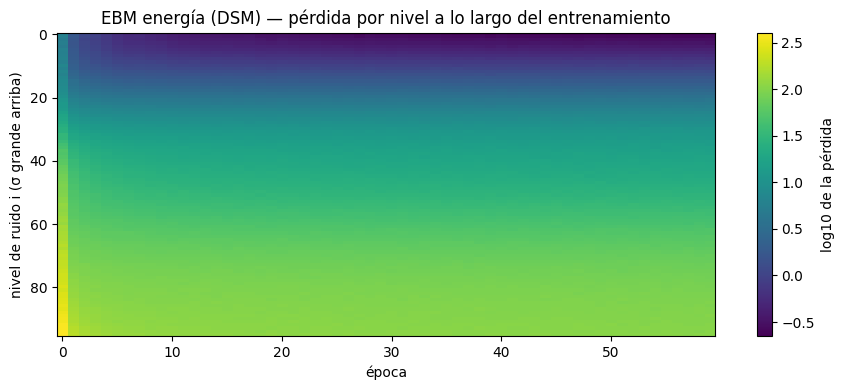

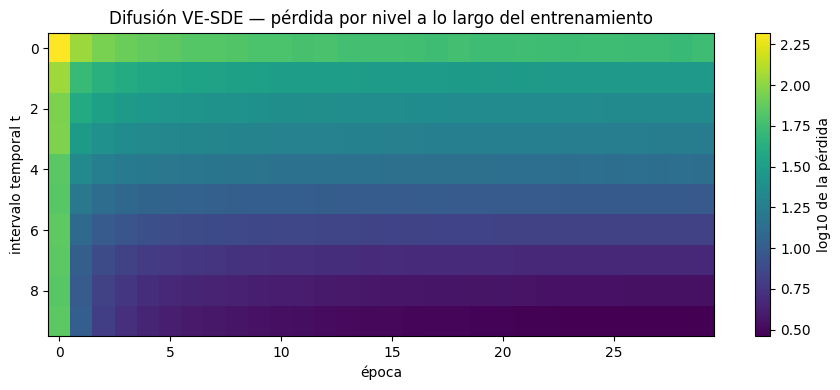

In [ ]:

for nombre in disponibles:
    h_ep = historiales[nombre]["hist_ep"]

    if "loss_per_sigma" in h_ep:
        matriz = np.array(h_ep["loss_per_sigma"], dtype=float)
        etiqueta_y = "nivel de ruido i (σ grande arriba)"
    elif "loss_per_t" in h_ep:
        matriz = np.array(h_ep["loss_per_t"], dtype=float)
        etiqueta_y = "intervalo temporal t"
    else:
        continue

    plt.figure(figsize=(9, 4))
    plt.imshow(
        np.log10(matriz.T + 1e-12),
        aspect="auto",
        origin="upper",
        cmap="viridis",
    )
    plt.colorbar(label="log10 de la pérdida")
    plt.xlabel("época")
    plt.ylabel(etiqueta_y)
    plt.title(f"{nombre} — pérdida por nivel a lo largo del entrenamiento")
    plt.tight_layout()
    guardar_fig(f"mapa_calor_{slug(nombre)}")
    plt.show()

## Coste

In [22]:
NFE = {
    "PCD": None,
    "EBM energía (DSM)": None,
    "Difusión VE-SDE": None,
}

if "PCD" in disponibles:
    NFE["PCD"] = configs["PCD"]["gen_steps"]

if "EBM energía (DSM)" in disponibles:
    cfg = configs["EBM energía (DSM)"]
    # L niveles x T pasos, más el paso final de denoising
    NFE["EBM energía (DSM)"] = len(sigmas_dsm) * cfg["T"] + 1

if "Difusión VE-SDE" in disponibles:
    NFE["Difusión VE-SDE"] = configs["Difusión VE-SDE"]["n_steps"]

tabla_coste = {}

for nombre in disponibles:
    h_ep = historiales[nombre]["hist_ep"]
    tiempos = np.asarray(h_ep["time_s"], dtype=float)

    tabla_coste[nombre] = dict(
        parametros=n_parametros[nombre],
        epocas=len(tiempos),
        s_por_epoca=float(tiempos.mean()),
        total_entrenamiento_min=float(tiempos.sum() / 60),
        nfe=NFE[nombre],
        s_por_1000_muestras=tiempos_muestreo[nombre] / CFG["n_muestras"] * 1000,
    )

    t = tabla_coste[nombre]
    print(f"{nombre:22s} {t['parametros']:>9,} par. | "
          f"{t['epocas']:3d} épocas | "
          f"{t['s_por_epoca']:6.1f} s/época | "
          f"{t['total_entrenamiento_min']:6.1f} min | "
          f"NFE {t['nfe']:5d} | "
          f"{t['s_por_1000_muestras']:8.1f} s/1000 muestras")

PCD                       76,993 par. |  60 épocas |   53.4 s/época |   53.4 min | NFE   256 |      1.1 s/1000 muestras
EBM energía (DSM)      1,980,929 par. |  60 épocas |   28.2 s/época |   28.2 min | NFE   481 |     25.9 s/1000 muestras
Difusión VE-SDE        1,115,425 par. |  30 épocas |   17.3 s/época |    8.6 min | NFE  2000 |    111.6 s/1000 muestras


## Rejillas visuales

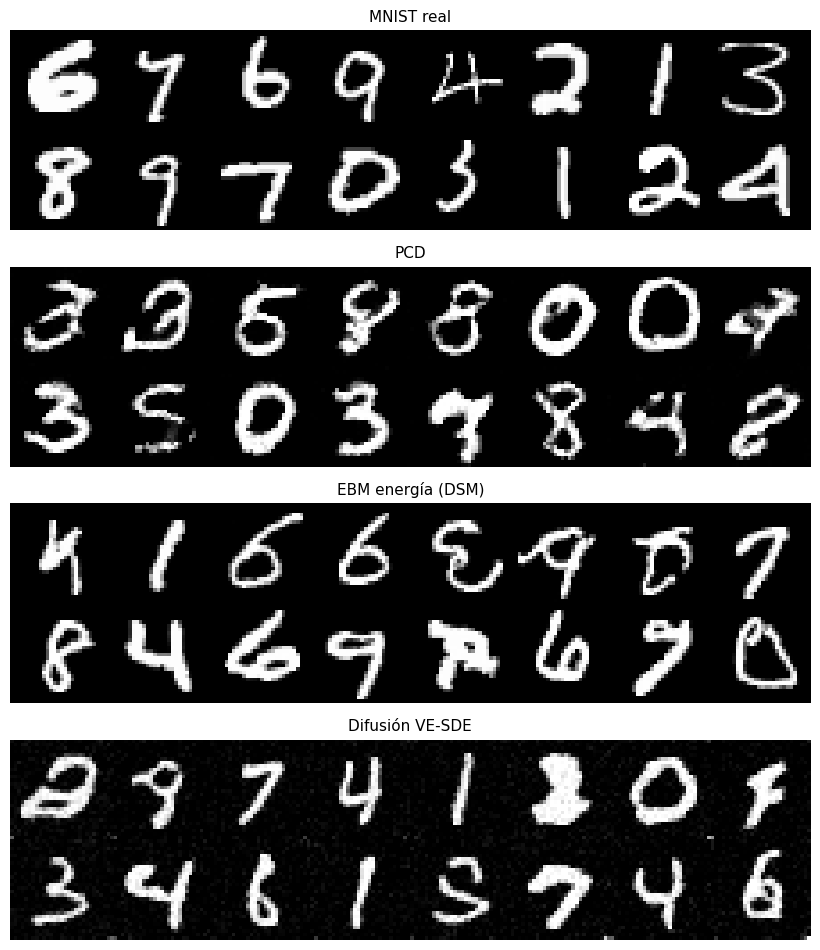

In [23]:
n_fila = 8
n_mostrar = 16

paneles = {"MNIST real": real_A[:n_mostrar],
           **{n: muestras[n][:n_mostrar] for n in disponibles}}

fig, axes = plt.subplots(len(paneles), 1, figsize=(9, 2.4 * len(paneles)))
if len(paneles) == 1:
    axes = [axes]

for ax_i, (nombre, x) in zip(axes, paneles.items()):
    filas = x[:n_mostrar].reshape(n_mostrar // n_fila, n_fila, 28, 28)
    mosaico = filas.permute(0, 2, 1, 3).reshape(-1, n_fila * 28)
    ax_i.imshow(mosaico.numpy(), cmap="gray", vmin=0, vmax=1)
    ax_i.set_title(nombre, fontsize=11)
    ax_i.axis("off")

plt.tight_layout()
guardar_fig("rejillas_comparacion")
plt.show()

## Tabla resumen y guardado

In [24]:
resumen = {
    "config": CFG,
    "precision_clasificador": precision_clf,
    "n_muestras": CFG["n_muestras"],
    "distribucion": tabla_distribucion,
    "clasificador": tabla_clasificador,
    "diversidad": tabla_diversidad,
    "estabilidad": tabla_estabilidad,
    "coste": tabla_coste,
}

ruta_resumen = dir_salida / "resumen_comparacion.json"

with ruta_resumen.open("w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=2, ensure_ascii=False)

print("guardado en", ruta_resumen)
print()
print([p.name for p in sorted(dir_salida.iterdir())])

guardado en /content/drive/MyDrive/tfg_copia/results/comparacion/resumen_comparacion.json

['clases_y_confianza.png', 'clasificador_mnist.pt', 'curvas_perdida.png', 'estabilidad_entrenamiento.png', 'mapa_calor_difusion_ve_sde.png', 'mapa_calor_ebm_energia__dsm.png', 'memorizacion_difusion_ve_sde.png', 'memorizacion_ebm_energia__dsm.png', 'memorizacion_pcd.png', 'muestras_difusion_ve_sde.pt', 'muestras_ebm_energia__dsm.pt', 'muestras_pcd.pt', 'pcd_separacion_energias.png', 'rejillas_comparacion.png', 'resumen_comparacion.json']


In [25]:
# Tabla final en texto, lista para copiar a la memoria
cabecera = (
    f"{'conjunto':28s} {'FID':>9s} {'KID':>10s} {'P':>6s} {'R':>6s} "
    f"{'conf':>6s} {'entr':>6s} {'TV':>6s} {'IS':>6s}"
)
print(cabecera)
print("-" * len(cabecera))

for nombre in conjuntos:
    d = tabla_distribucion[nombre]
    c = tabla_clasificador[nombre]
    print(
        f"{nombre:28s} {d['fid']:9.3f} {d['kid']:10.5f} "
        f"{d['precision']:6.3f} {d['recall']:6.3f} "
        f"{c['confianza']:6.3f} {c['entropia']:6.3f} "
        f"{c['tv']:6.3f} {c['mnist_is']:6.3f}"
    )

conjunto                           FID        KID      P      R   conf   entr     TV     IS
-------------------------------------------------------------------------------------------
MNIST mitad B (referencia)       0.629   -1.16919  0.897  0.901  0.983  0.999  0.021  9.468
PCD                            123.140  426.68412  0.686  0.845  0.906  0.923  0.247  6.560
EBM energía (DSM)               16.419   26.23579  0.717  0.954  0.923  0.987  0.093  7.880
Difusión VE-SDE                 25.000   44.93770  0.732  0.863  0.910  0.985  0.120  7.589
